# Evaluación de la deformación superficial asociada a movimientos en masa mediante análisis InSAR y datos GNSS en la cuenca media y baja del río Suárez, Colombia

## Notebook 3 de 3. Integración de InSAR y GNSS

**Autores:** Mariana Paredes Galindo · Sair Granada Garzón  
Universidad Industrial de Santander · Escuela de Geología · Bucaramanga, 2026

Seis celdas de código hacen todo: preparan el entorno y el diseño, calculan la velocidad GNSS de cada estación en el periodo de las imágenes, la proyectan a la línea de vista (LOS) de cada geometría (Hanssen, 2001; Yunjun et al., 2019), la comparan con la velocidad InSAR de la estación y dibujan una figura por estación. Los valores positivos indican que el terreno se acerca al satélite.

Cada figura tiene una fila por geometría: la cuenca con la ventana del acercamiento resaltada, el mapa del acercamiento con la escala de −60 a +60 mm/año y el gráfico XY de las series InSAR y GNSS en la línea de vista. Salen tres tablas (velocidades GNSS por estación, comparación en LOS y concordancia entre técnicas). Todo se guarda en `03_resultados/integracion/`.

Requiere los resultados del notebook 1 (mosaicos, GeoTIFF de ángulos y `series_puntos.csv`) y del notebook 2 (`velocidades_gnss.csv` y el archivo de saltos).

## 1. Preparación: librerías, parámetros, estilo y funciones de lectura

**Qué hace esta celda.** Importa las librerías (instala las que falten), define las rutas del proyecto y los parámetros del análisis. No produce tablas ni figuras. Las dos celdas siguientes dejan listos el diseño de las figuras y las funciones que leen los GeoTIFF, las series diarias GNSS (`.tenv3`), las velocidades del notebook 2 y las épocas de salto.

**Parámetros que se pueden cambiar:**

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| `START`, `END` | 2022-03-01 a 2026-09-30 | Periodo de las imágenes; la velocidad GNSS se recalcula solo en él |
| `RADIOS_INSAR_M` | 500, 1000, 2000 m | La mediana InSAR de la estación se toma en el primer radio que tenga píxeles suficientes |
| `MIN_PX_INSAR` | 5 | Mínimo de píxeles confiables dentro del radio |
| `REFERENCIA_INSAR` | OAMU | Estación sobre el punto de referencia de MintPy; queda fuera de las estadísticas |
| `MIN_DIAS_PERIODO`, `MIN_ANIOS_PERIODO` | 200 días; 1 año | Datos GNSS mínimos en el periodo para calcular su velocidad |
| `USAR_REGISTRO_COMPLETO` | `True` | Si no alcanza, usa la velocidad del registro completo del notebook 2 y lo indica |
| `RADIO_ZOOM_KM` | 3 km | Medio ancho de la ventana del acercamiento |
| `LIM_VEL` | 60 mm/año | Escala de colores, de −60 (azul) a +60 (rojo) |

In [1]:
# Dependencias: instala solo las que falten
import importlib.util
import subprocess
import sys

faltantes = [p for p in ("geopandas", "pyproj", "rasterio") if importlib.util.find_spec(p) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])

import html
from pathlib import Path

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import HTML, display
from matplotlib import font_manager
from matplotlib.lines import Line2D
from pyproj import Transformer
from scipy import linalg

# ---------------------------------------------------------------- parametros
BASE_DIR = Path.home() / "Tesis_InSAR_Rio_Suarez"
RUN_ID = "suarez_2024_2026_v1"
ARCHIVO_AREA = BASE_DIR / "01_datos" / "area_estudio" / "Cuenca_RioMedioyBajoSuarez.shp"
SERIES_GNSS_DIR = BASE_DIR / "01_datos" / "gnss"
GEOTIFF_DIR = BASE_DIR / "03_resultados" / "geotiff"
MOSAICO_DIR = GEOTIFF_DIR / "mosaicos"
RESULTADOS_GNSS_DIR = BASE_DIR / "03_resultados" / "gnss"
ARCHIVO_SERIES_INSAR = BASE_DIR / "03_resultados" / "tablas" / f"{RUN_ID}_series_puntos.csv"
SALIDA_DIR = BASE_DIR / "03_resultados" / "integracion"
FIGURAS_DIR = SALIDA_DIR / "figuras"

START, END = "2022-03-01", "2026-09-30"
GEOMETRIAS = {"DESCENDING_R69": ["DESCENDING_R69_F572", "DESCENDING_R69_F567"], "ASCENDING_R77": ["ASCENDING_R77_F1199"]}
NOMBRE_GEOMETRIA = {"DESCENDING_R69": "Descendente", "ASCENDING_R77": "Ascendente"}
RADIOS_INSAR_M = (500, 1000, 2000)  # se usa el primero que tenga al menos MIN_PX_INSAR pixeles confiables
MIN_PX_INSAR = 5
REFERENCIA_INSAR = "OAMU"
MIN_DIAS_PERIODO, MIN_ANIOS_PERIODO, MIN_PUNTOS_LADO = 200, 1.0, 30
USAR_REGISTRO_COMPLETO = True
MAX_HUECO_DIAS, VENTANA_MEDIANA_GNSS = 30, 15
RADIO_ZOOM_KM = 3
LIM_VEL, PALETA = 60, "RdBu_r"
SITIOS_GNSS = {
    "CHRL": (6.287477, -73.156451), "PATU": (5.74649545, -73.12566732), "SUAM": (5.709874625, -72.92469695),
    "VMES": (6.88333419, -73.09168234), "VELZ": (5.957135, -73.646586), "FLRN": (5.807812, -73.971958),
    "VBUV": (5.533208338, -73.85893524), "TUNA": (5.531330417, -73.36388193), "AGTU": (5.519884547, -73.37370225),
    "OAMU": (5.647208907, -73.55802943), "TEAT": (5.421783709, -73.53931227), "FQNE": (5.467344957, -73.73480849),
}

for carpeta in (SALIDA_DIR, FIGURAS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)


### Diseño de figuras y tablas

Esta celda es la misma en los tres notebooks, para que todo el trabajo se vea igual. Fija la fuente (Times New Roman o la serif más parecida), la paleta (azul para lo que se aleja o desciende, rojo para lo que se acerca o asciende, gris para los datos), el ancho de 6,5 pulgadas, las marcas de los ejes hacia adentro y las letras de panel en recuadros blancos. Los títulos de figura y de tabla llevan solo el número y el nombre; lo que cada una muestra se explica en el texto de su celda. Las figuras se guardan en PNG y PDF a 300 dpi en la carpeta de figuras.

In [2]:
# Diseño común de los tres notebooks: fuente, paleta, estilo de los ejes, títulos de figura y tablas
import html

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from matplotlib import font_manager

# Fuente: Times New Roman o la serif más parecida que esté instalada
FUENTES = ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"]
instaladas = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next(f for f in FUENTES if f in instaladas or f == "DejaVu Serif")

# Medidas y colores
FIG_ANCHO = 6.5            # pulgadas, ancho útil de la página
ESCALA_KM = 20             # longitud de la escala gráfica de los mapas, km
FONDO = "#ececec"
COLOR_AZUL, COLOR_ROJO, COLOR_DATOS, COLOR_NARANJA = "#2166ac", "#b2182b", "#9a9a9a", "#e08214"
PALETA_VELOCIDAD, PALETA_INCERTIDUMBRE = "RdBu_r", "magma_r"

plt.rcParams.update({
    "font.family": "serif", "font.serif": [FUENTE], "mathtext.fontset": "stix", "font.size": 8,
    "axes.linewidth": 0.8, "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.titlesize": 9,
    "axes.axisbelow": True, "grid.color": "0.88", "grid.linewidth": 0.5, "lines.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "legend.fontsize": 7, "legend.framealpha": 0.9, "legend.edgecolor": "0.8",
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white", "pdf.fonttype": 42,
})
TIPO_HTML = "font-family:'Times New Roman',Times,serif;font-size:13px"


# Número con coma decimal
def coma(valor, decimales=1):
    return f"{valor:.{decimales}f}".replace(".", ",")


# Grados decimales a texto en grados y minutos con hemisferio
def gms(valor, positivo, negativo):
    total = round(abs(valor) * 60)
    return f"{total // 60}°{total % 60:02d}'{positivo if valor >= 0 else negativo}"


# Letra del panel en un recuadro blanco
def letra_panel(eje, letra, x=0.03, y=0.965):
    eje.text(x, y, letra, transform=eje.transAxes, ha="left", va="top", fontsize=9, fontweight="bold",
             bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="black", lw=0.6), zorder=6)


# Marcas hacia adentro en los cuatro bordes y borde de 0,8 pt
def estilo_eje(eje):
    eje.tick_params(labelsize=7, direction="in", length=3, top=True, right=True)
    for borde in eje.spines.values():
        borde.set_linewidth(0.8)


# Marcas de longitud en el borde inferior y de latitud en el izquierdo, en grados y minutos
def coordenadas_geograficas(eje, epsg, paso_x, paso_y):
    from pyproj import Transformer
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    a_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    a_map = Transformer.from_crs(4326, epsg, always_xy=True)
    lon_min, lat_min = a_geo.transform(x0, y0)
    lon_max, lat_max = a_geo.transform(x1, y1)
    _, lat_borde = a_geo.transform((x0 + x1) / 2, y0)
    lon_borde, _ = a_geo.transform(x0, (y0 + y1) / 2)
    lons = np.arange(np.ceil(lon_min / paso_x) * paso_x, lon_max, paso_x)
    lats = np.arange(np.ceil(lat_min / paso_y) * paso_y, lat_max, paso_y)
    xs = [(a_map.transform(lon, lat_borde)[0], lon) for lon in lons]
    ys = [(a_map.transform(lon_borde, lat)[1], lat) for lat in lats]
    xs = [(x, v) for x, v in xs if x0 + 0.04 * (x1 - x0) < x < x1 - 0.04 * (x1 - x0)]
    ys = [(y, v) for y, v in ys if y0 + 0.03 * (y1 - y0) < y < y1 - 0.03 * (y1 - y0)]
    eje.set_xticks([x for x, _ in xs])
    eje.set_xticklabels([gms(v, "E", "W") for _, v in xs])
    eje.set_yticks([y for y, _ in ys])
    eje.set_yticklabels([gms(v, "N", "S") for _, v in ys], rotation=90, va="center")


# Norte en la esquina superior derecha y escala gráfica en la inferior izquierda, sobre recuadros blancos (mapa en metros)
def norte_y_escala(eje, escala_km=ESCALA_KM):
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    ancho, alto = x1 - x0, y1 - y0
    bx, by, largo = x0 + 0.08 * ancho, y0 + 0.04 * alto, escala_km * 1000
    eje.add_patch(plt.Rectangle((bx - 0.05 * ancho, by - 0.017 * alto), largo + 0.24 * ancho, 0.06 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    for i in range(2):
        eje.add_patch(plt.Rectangle((bx + i * largo / 2, by), largo / 2, 0.009 * alto,
                                    facecolor="black" if i == 0 else "white", edgecolor="black", lw=0.4, zorder=5))
    for v, x in ((0, bx), (escala_km // 2, bx + largo / 2), (escala_km, bx + largo)):
        eje.text(x, by + 0.014 * alto, f"{v}", ha="center", va="bottom", fontsize=5.5, zorder=5)
    eje.text(bx + largo + 0.04 * ancho, by + 0.005 * alto, "km", va="center", fontsize=5.5, zorder=5)
    nx, ny = x1 - 0.1 * ancho, y1 - 0.12 * alto
    eje.add_patch(plt.Rectangle((nx - 0.055 * ancho, ny - 0.01 * alto), 0.11 * ancho, 0.1 * alto,
                                facecolor="white", edgecolor="black", lw=0.4, alpha=0.9, zorder=4))
    eje.annotate("", xy=(nx, ny + 0.055 * alto), xytext=(nx, ny + 0.002 * alto),
                 arrowprops=dict(facecolor="black", edgecolor="black", width=1.5, headwidth=4.5, headlength=4), zorder=5)
    eje.text(nx, ny + 0.058 * alto, "N", ha="center", va="bottom", fontsize=6.5, fontweight="bold", zorder=5)


# Barra de colores horizontal con rótulo; con límite, marcas cada 10 unidades
def barra_colores(fig, imagen, ejes, rotulo, limite=None, encoger=0.6):
    marcas = range(-limite, limite + 1, 10) if limite else None
    barra = fig.colorbar(imagen, ax=ejes, orientation="horizontal", shrink=encoger, pad=0.02, aspect=40, ticks=marcas)
    barra.set_label(rotulo, fontsize=8)
    barra.ax.tick_params(labelsize=7)
    return barra


# Título de una figura: "Figura N" en negrita (si se da el número) y el título en cursiva
def titulo_figura(titulo, numero=None):
    cabeza = f'<div style="font-weight:bold">Figura {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 2px">{cabeza}'
                 f'<div style="font-style:italic">{html.escape(titulo)}</div></div>'))


# Guarda la figura en PNG y PDF dentro de FIGURAS_DIR y, si se da título, lo muestra encima de ella
def guardar_figura(fig, nombre, titulo=None, numero=None):
    if titulo:
        titulo_figura(titulo, numero)
    for extension in ("png", "pdf"):
        fig.savefig(FIGURAS_DIR / f"{nombre}.{extension}")


# Texto de una celda de tabla: coma decimal, decimales parejos por columna y guion para los vacíos
def texto_celda(valor, decimales):
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "-"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:,.{decimales}f}".replace(",", " ").replace(".", ",")
    if isinstance(valor, (int, np.integer)):
        return f"{valor:,}".replace(",", " ") if abs(valor) >= 10000 else str(valor)
    return html.escape(str(valor))


# Tabla en formato APA 7: número (opcional), título en cursiva y solo líneas horizontales.
# Con agrupar="Columna", los valores repetidos de esa primera columna salen una sola vez y los grupos se separan con una línea fina
def tabla_apa(tabla, titulo, numero=None, agrupar=None):
    if tabla is None or len(tabla) == 0:
        return
    linea, fina = "1.5px solid currentColor", "1px solid #bbbbbb"
    decimales = {}
    for col in tabla.columns:
        valores = [v for v in tabla[col] if isinstance(v, (float, np.floating)) and np.isfinite(v)]
        partes = [f"{round(float(v), 2)}".split(".")[1] for v in valores]
        decimales[col] = max([1] + [len(p.rstrip("0")) for p in partes])
    cabeza = "".join(f'<th style="border-top:{linea};border-bottom:1px solid currentColor;padding:3px 10px;'
                     f'font-weight:normal;text-align:center">{html.escape(str(col))}</th>' for col in tabla.columns)
    inicios, tamanos = {}, {}
    if agrupar is not None:
        grupo = list(tabla[agrupar])
        for k, v in enumerate(grupo):
            if k == 0 or v != grupo[k - 1]:
                inicios[k], actual = v, k
                tamanos[k] = 0
            tamanos[actual] += 1
    filas, ultimo = [], len(tabla) - 1
    for k, (_, fila) in enumerate(tabla.iterrows()):
        borde = f"border-bottom:{linea};" if k == ultimo else ""
        if agrupar is not None and k in inicios and k > 0:
            borde += f"border-top:{fina};"
        celdas = []
        for col in tabla.columns:
            valor = fila[col]
            if col == agrupar:
                if k in inicios:
                    cierre = f"border-bottom:{linea};" if k + tamanos[k] - 1 == ultimo else ""
                    sup = f"border-top:{fina};" if k > 0 else ""
                    celdas.append(f'<td rowspan="{tamanos[k]}" style="{cierre}{sup}padding:2px 10px;text-align:left;'
                                  f'vertical-align:top;font-weight:bold">{texto_celda(valor, 0)}</td>')
                continue
            alinear = "right" if isinstance(valor, (int, float, np.integer, np.floating)) else "left"
            celdas.append(f'<td style="{borde}padding:2px 10px;text-align:{alinear}">{texto_celda(valor, decimales[col])}</td>')
        filas.append("<tr>" + "".join(celdas) + "</tr>")
    encabezado = f'<div style="font-weight:bold">Tabla {numero}</div>' if numero is not None else ""
    display(HTML(f'<div style="{TIPO_HTML};margin:12px 0 14px">{encabezado}'
                 f'<div style="font-style:italic;margin-bottom:4px">{html.escape(titulo)}</div>'
                 f'<table style="border-collapse:collapse;{TIPO_HTML}"><thead><tr>{cabeza}</tr></thead>'
                 f'<tbody>{"".join(filas)}</tbody></table></div>'))


print(f"ok: diseño cargado | fuente de las figuras: {FUENTE}")

ok: diseño cargado | fuente de las figuras: Liberation Serif


### Funciones de lectura

Leen un GeoTIFF, buscan la capa de cada geometría (mosaico recortado, mosaico completo o GeoTIFF del primer stack que la tenga), leen las series diarias `.tenv3` del NGL y normalizan las velocidades y las épocas de salto que entrega el notebook 2, aunque vengan de una versión anterior.

In [3]:
# Colores de cada geometría: la serie InSAR en azul (descendente) o rojo (ascendente), con un tono claro para la mediana móvil
COLORES_STACK = {"DESCENDING": [COLOR_AZUL, "#5aa0d0"], "ASCENDING": [COLOR_ROJO, "#e06a5a"]}


# ---------------------------------------------------------------- lectura
# Lee un GeoTIFF: arreglo con NaN en los vacios, extension (izquierda, derecha, abajo, arriba) y EPSG
def leer_raster(ruta):
    with rasterio.open(ruta) as src:
        arr = src.read(1).astype(float)
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        b = src.bounds
        return arr, [b.left, b.right, b.bottom, b.top], src.crs.to_epsg()


# Ruta de una capa: mosaico recortado, mosaico completo o GeoTIFF del primer stack de la geometria que la tenga
def ruta_capa(capa, geometria, sufijos=("_area", "")):
    candidatas = [MOSAICO_DIR / f"{capa}_{geometria}{s}.tif" for s in sufijos]
    for stack in GEOMETRIAS[geometria]:
        candidatas += [GEOTIFF_DIR / f"{RUN_ID}_{stack}" / f"{capa}{s}.tif" for s in sufijos]
    for ruta in candidatas:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(f"no hay {capa} de {geometria} en {MOSAICO_DIR} ni en los stacks")


# Lee la serie diaria de una estacion en formato tenv3 del NGL (mm respecto a la mediana)
def leer_tenv3(ruta):
    tabla = pd.read_csv(ruta, sep=r"\s+", header=0)
    datos = pd.DataFrame({
        "fecha": pd.Timestamp("1858-11-17") + pd.to_timedelta(tabla.iloc[:, 3], unit="D"), "t": tabla.iloc[:, 2].astype(float),
        "e": (tabla.iloc[:, 7] + tabla.iloc[:, 8]) * 1000, "n": (tabla.iloc[:, 9] + tabla.iloc[:, 10]) * 1000,
        "u": (tabla.iloc[:, 11] + tabla.iloc[:, 12]) * 1000,
        "se": tabla.iloc[:, 14] * 1000, "sn": tabla.iloc[:, 15] * 1000, "su": tabla.iloc[:, 16] * 1000})
    for c in ("e", "n", "u"):
        datos[c] -= datos[c].median()
    return datos.dropna().reset_index(drop=True)


# Anio decimal de una fecha
def anio_decimal(fecha):
    return fecha.year + (fecha.dayofyear - 0.5) / (366 if fecha.is_leap_year else 365)


# Velocidades del notebook 2 con columnas normalizadas (acepta versiones anteriores)
def leer_velocidades(ruta):
    tabla = pd.read_csv(ruta)
    minusculas = {str(c).strip().lower(): c for c in tabla.columns}
    alias = {"estacion": ["estacion", "estación", "sitio"], "componente": ["componente"], "velocidad": ["velocidad", "v"],
             "error": ["error"], "interpretable": ["interpretable"], "dias": ["dias", "días"], "razon": ["razon", "razón"]}
    for destino, opciones in alias.items():
        origen = next((minusculas[o] for o in opciones if o in minusculas), None)
        if origen is not None:
            tabla = tabla.rename(columns={origen: destino})
    if not {"estacion", "componente", "velocidad", "error"} <= set(tabla.columns):
        print(f"aviso: velocidades_gnss.csv sin columnas esperadas ({list(tabla.columns)}); solo se usa el periodo de las imágenes")
        return pd.DataFrame(columns=["estacion", "componente", "velocidad", "error", "interpretable", "dias", "razon"])
    for columna, defecto in (("interpretable", True), ("dias", 0), ("razon", 1.0)):
        if columna not in tabla.columns:
            tabla[columna] = defecto
    return tabla


# Epocas de salto por estacion (anio decimal): del archivo de saltos del notebook 2, con columna t o fecha
def leer_epocas_saltos():
    for nombre in ("saltos_modelo_gnss.csv", "saltos_gnss.csv"):
        ruta = RESULTADOS_GNSS_DIR / nombre
        if not ruta.exists():
            continue
        tabla = pd.read_csv(ruta)
        tabla.columns = [str(c).strip().lower() for c in tabla.columns]
        if "significativo" in tabla.columns:
            tabla = tabla[tabla["significativo"].astype(str).str.lower().isin(["true", "1", "sí", "si", "yes"])]
        if "estacion" in tabla.columns and "t" in tabla.columns:
            return {e: g["t"].astype(float).to_numpy() for e, g in tabla.groupby("estacion")}
        if "estacion" in tabla.columns and "fecha" in tabla.columns:
            fechas = pd.to_datetime(tabla["fecha"], errors="coerce")
            tabla = tabla.assign(t=[anio_decimal(f) if pd.notna(f) else np.nan for f in fechas]).dropna(subset=["t"])
            return {e: g["t"].to_numpy() for e, g in tabla.groupby("estacion")}
    print("aviso: no hay archivo de saltos utilizable; las velocidades GNSS se ajustan sin saltos")
    return {}

## 2. Velocidad GNSS en el periodo de las imágenes

**Qué hace esta celda.** Para cada estación recalcula la velocidad este, norte y vertical solo con los datos de `START` a `END`, para que sea la del mismo periodo que InSAR. El ajuste es de mínimos cuadrados ponderados con tendencia, señal anual (y semestral si el periodo dura 2 años o más), descarte de atípicos a 3 desviaciones robustas y un escalón en cada época de salto del notebook 2 que tenga datos suficientes a ambos lados (Bevis y Brown, 2014). La incertidumbre se multiplica por la razón entre el error con ruido correlacionado y el de ruido blanco del notebook 2 (Williams, 2003).

**Salida: tabla de velocidades GNSS.** Cada fila es una estación; `Origen` dice si la velocidad sale del periodo de las imágenes (`periodo`), del registro completo (`registro completo`) o si no hay datos (`sin datos`); `Días` son las épocas usadas. Para analizar: las estaciones con `periodo` son comparables con InSAR; las de `registro completo` tienen otro intervalo de tiempo y deben leerse con cuidado. El archivo se guarda en `gnss_velocidades_periodo.csv`. El marco es IGS20.

In [4]:
# ---------------------------------------------------------------- GNSS en el periodo
# Matriz de diseno: constante, tendencia, armonicos y un escalon por salto
def matriz_periodo(t, saltos, armonicos):
    columnas = [np.ones_like(t), t - t.mean()]
    for k in range(1, armonicos + 1):
        columnas += [np.sin(2 * np.pi * k * t), np.cos(2 * np.pi * k * t)]
    columnas += [(t >= s).astype(float) for s in saltos]
    return np.column_stack(columnas)


# Minimos cuadrados ponderados: coeficientes, covarianza escalada y residuos
def mcp(X, y, s):
    w = 1 / s
    beta = linalg.lstsq(X * w[:, None], y * w)[0]
    resid = y - X @ beta
    escala = np.sqrt(np.sum((resid * w) ** 2) / max(len(y) - X.shape[1], 1))
    cov = np.linalg.pinv((X * w[:, None]).T @ (X * w[:, None])) * escala ** 2
    return beta, cov, resid


# Ajuste de un componente en el periodo: (velocidad, error, datos usados, y sin escalones) o None si no hay datos suficientes
def ajustar_periodo(t, y, s, epocas, razon):
    dentro = (t >= anio_decimal(pd.Timestamp(START))) & (t <= anio_decimal(pd.Timestamp(END)))
    t, y, s = t[dentro], y[dentro], s[dentro]
    if len(t) < MIN_DIAS_PERIODO or t.max() - t.min() < MIN_ANIOS_PERIODO:
        return None
    saltos = [x for x in epocas if (t < x).sum() >= MIN_PUNTOS_LADO and (t >= x).sum() >= MIN_PUNTOS_LADO]
    armonicos = 2 if t.max() - t.min() >= 2 else 1
    valido = np.ones(len(t), dtype=bool)
    for _ in range(5):
        X = matriz_periodo(t, saltos, armonicos)
        beta, cov, _ = mcp(X[valido], y[valido], s[valido])
        completo = y - X @ beta
        sigma = 1.4826 * np.median(np.abs(completo[valido] - np.median(completo[valido])))
        nuevo = np.abs(completo) < 3 * sigma
        if np.array_equal(nuevo, valido):
            break
        valido = nuevo
    escalones = X[:, 2 + 2 * armonicos:] @ beta[2 + 2 * armonicos:]
    return float(beta[1]), float(np.sqrt(cov[1, 1]) * razon), int(valido.sum()), (t, y - escalones)


velocidades = leer_velocidades(RESULTADOS_GNSS_DIR / "velocidades_gnss.csv")
epocas_saltos = leer_epocas_saltos()
COMPONENTES = (("e", "Este", "se"), ("n", "Norte", "sn"), ("u", "Vertical", "su"))
filas, series_gnss = [], {}
for estacion in SITIOS_GNSS:
    ruta = SERIES_GNSS_DIR / f"{estacion}.tenv3"
    fila = {"Estación": estacion, "Origen": "sin datos", "Días": 0}
    v, e = np.full(3, np.nan), np.full(3, np.nan)
    if ruta.exists():
        datos = leer_tenv3(ruta)
        t = datos["t"].to_numpy()
        sin_saltos = {}
        for k, (comp, nombre, err) in enumerate(COMPONENTES):
            razon = velocidades.loc[(velocidades["estacion"] == estacion) & (velocidades["componente"] == nombre), "razon"]
            res = ajustar_periodo(t, datos[comp].to_numpy(), datos[err].to_numpy(), epocas_saltos.get(estacion, []),
                                  float(razon.iloc[0]) if len(razon) else 1.0)
            if res is not None:
                v[k], e[k], fila["Días"] = res[0], res[1], res[2]
                fila["Origen"] = "periodo"
                sin_saltos[comp] = res[3]
        if len(sin_saltos) == 3:
            tt = sin_saltos["e"][0]
            fechas = pd.DatetimeIndex(datos["fecha"][(datos["t"] >= tt.min()) & (datos["t"] <= tt.max())])
            if len(fechas) == len(tt):
                series_gnss[estacion] = (fechas, {c: sin_saltos[c][1] for c in sin_saltos})
    if fila["Origen"] != "periodo" and USAR_REGISTRO_COMPLETO:
        sub = velocidades[(velocidades["estacion"] == estacion) & velocidades["interpretable"].astype(bool)]
        if len(sub) == 3:
            for k, nombre in enumerate(("Este", "Norte", "Vertical")):
                fc = sub[sub["componente"] == nombre].iloc[0]
                v[k], e[k] = fc["velocidad"], fc["error"]
            fila["Origen"], fila["Días"] = "registro completo", int(sub["dias"].min())
    fila.update({"VE": v[0], "VN": v[1], "VU": v[2], "σVE": e[0], "σVN": e[1], "σVU": e[2]})
    filas.append(fila)

gnss = pd.DataFrame(filas)
gnss.to_csv(SALIDA_DIR / "gnss_velocidades_periodo.csv", index=False, encoding="utf-8-sig")
tabla_apa(gnss.rename(columns={"VE": "Este (mm/año)", "VN": "Norte (mm/año)", "VU": "Vertical (mm/año)"})
          [["Estación", "Origen", "Días", "Este (mm/año)", "Norte (mm/año)", "Vertical (mm/año)"]],
          "Velocidad GNSS de cada estación en el periodo de las imágenes")
usables = gnss[np.isfinite(gnss["VE"])]

Estación,Origen,Días,Este (mm/año),Norte (mm/año),Vertical (mm/año)
CHRL,periodo,448,"7,17","13,64","-1,73"
PATU,registro completo,874,"23,34","18,28","0,37"
SUAM,periodo,414,"0,49","9,12","-9,65"
VMES,periodo,313,"3,00","13,81","-4,89"
VELZ,periodo,496,"6,80","15,48","-3,34"
FLRN,periodo,310,"5,92","-11,10","-4,67"
VBUV,sin datos,0,-,-,-
TUNA,periodo,829,"1,95","11,59","-4,68"
AGTU,periodo,209,"2,33","9,13","-3,43"
OAMU,sin datos,0,-,-,-


## 3. InSAR en las estaciones y comparación en la línea de vista

**Qué hace esta celda.** Lee los mosaicos de velocidad InSAR sin recortar a la cuenca (velocidad total y velocidad local) y, para cada estación y geometría:

1. toma la mediana InSAR de los píxeles confiables dentro del primer radio de `RADIOS_INSAR_M` que tenga al menos `MIN_PX_INSAR` píxeles;
2. proyecta la velocidad GNSS a la línea de vista (LOS) con el vector unitario de MintPy, positivo hacia el satélite, $\hat{u} = (-\sin\theta \sin\alpha,\ \sin\theta \cos\alpha,\ \cos\theta)$ (Hanssen, 2001; Yunjun et al., 2019), donde la incidencia θ y el azimut α salen de los GeoTIFF del notebook 1;
3. calcula la diferencia InSAR menos GNSS.

**Salidas para analizar:**

- **Estaciones sin comparación.** La celda imprime las que no se pudieron comparar y el motivo (sin GNSS, sin píxeles confiables o sin ángulos); el detalle de píxeles por radio queda en `estaciones_con_y_sin_comparacion.csv`.
- **Velocidad GNSS en LOS y velocidad InSAR por estación.** Valores positivos: el terreno se acerca al satélite. `Diferencia InSAR - GNSS` cercana a cero indica que las dos técnicas coinciden; una diferencia grande y constante entre estaciones sugiere un desfase de referencia (InSAR es relativo al punto de referencia y GNSS es absoluto), mientras que una diferencia que cambia entre estaciones apunta a deformación local que solo una de las técnicas ve. `InSAR local` es la velocidad sin la componente regional.
- **Concordancia entre técnicas.** Diferencia media, RMSE relativo (desviación de la diferencia respecto a su media; necesita dos o más estaciones) y Pearson (tres o más), sin la estación de referencia. Con pocas estaciones son cifras frágiles y se leen junto con la tabla anterior (Hu et al., 2014).

Los resultados quedan en `gnss_vs_insar_los.csv` y `sintesis_integracion.csv`. Las tablas llevan solo su título; el radio de cada fila es la distancia a la estación dentro de la cual se tomó la mediana InSAR, y el RMSE relativo y el Pearson excluyen la estación de referencia.

In [5]:
# ---------------------------------------------------------------- InSAR y comparacion en la linea de vista
gdf_area = gpd.read_file(ARCHIVO_AREA).to_crs(4326)
mapas = {}
for geometria in GEOMETRIAS:
    # Se usa el mosaico completo, sin recortar a la cuenca, para que las estaciones que quedan fuera tambien tengan InSAR
    local, extension, epsg = leer_raster(ruta_capa("velocidad_local_mm_anio", geometria, ("", "_area")))
    total, _, _ = leer_raster(ruta_capa("velocidad_mm_anio", geometria, ("", "_area")))
    mapas[geometria] = {"local": local, "total": total, "extension": extension, "epsg": epsg,
                        "local_s": local, "total_s": total, "extension_s": extension}


# Mediana de un raster dentro del primer radio de RADIOS_INSAR_M con al menos MIN_PX_INSAR pixeles: (valor, pixeles, radio)
def mediana_cerca(arr, extension, epsg, lat, lon, radios=RADIOS_INSAR_M):
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    izq, der, aba, arriba = extension
    filas_, cols = arr.shape
    dx, dy = (der - izq) / cols, (arriba - aba) / filas_
    col, fila = int((x - izq) / dx), int((arriba - y) / dy)
    n = 0
    for radio in radios:
        r = int(np.ceil(radio / dx))
        f0, f1, c0, c1 = max(fila - r, 0), min(fila + r + 1, filas_), max(col - r, 0), min(col + r + 1, cols)
        if f0 >= f1 or c0 >= c1:
            return np.nan, 0, radio
        ff, cc = np.indices((f1 - f0, c1 - c0))
        cerca = np.hypot((cc + c0 + 0.5) * dx + izq - x, arriba - (ff + f0 + 0.5) * dy - y) <= radio
        valores = arr[f0:f1, c0:c1][cerca]
        valores = valores[np.isfinite(valores)]
        n = len(valores)
        if n >= MIN_PX_INSAR:
            return float(np.median(valores)), n, radio
    return np.nan, n, radios[-1]


capas_angulos = {}


# Incidencia y azimut de la linea de vista en una estacion, del primer stack de la geometria que la cubra
def angulos_en_estacion(geometria, lat, lon):
    for stack in GEOMETRIAS[geometria]:
        carpeta = GEOTIFF_DIR / f"{RUN_ID}_{stack}"
        valores = []
        for nombre in ("incidencia_grados", "azimut_grados"):
            ruta = carpeta / f"{nombre}.tif"
            if not ruta.exists():
                break
            if ruta not in capas_angulos:
                capas_angulos[ruta] = leer_raster(ruta)
            valores.append(mediana_cerca(*capas_angulos[ruta], lat, lon, radios=(1000, 3000))[0])
        if len(valores) == 2 and np.isfinite(valores).all():
            return valores
    return None, None


# Vector unitario este, norte y arriba de la linea de vista, positivo hacia el satelite (convencion de MintPy)
def vector_los(incidencia, azimut):
    inc, az = np.deg2rad(incidencia), np.deg2rad(azimut)
    return np.array([-np.sin(inc) * np.sin(az), np.sin(inc) * np.cos(az), np.cos(inc)])


filas, motivos = [], []
for geometria, mapa in mapas.items():
    for _, e in gnss.iterrows():
        lat, lon = SITIOS_GNSS[e["Estación"]]
        insar, n_px, radio = mediana_cerca(mapa["total_s"], mapa["extension_s"], mapa["epsg"], lat, lon)
        conteos = [mediana_cerca(mapa["total_s"], mapa["extension_s"], mapa["epsg"], lat, lon, radios=(r,), )[1] for r in RADIOS_INSAR_M]
        local = mediana_cerca(mapa["local_s"], mapa["extension_s"], mapa["epsg"], lat, lon, radios=(radio,))[0]
        inc, az = angulos_en_estacion(geometria, lat, lon)
        motivo = ("sin velocidad GNSS" if not np.isfinite(e["VE"]) else "sin píxeles InSAR confiables" if not np.isfinite(insar)
                  else "sin ángulos de la línea de vista" if inc is None else "ok")
        motivos.append({"Geometría": NOMBRE_GEOMETRIA[geometria], "Estación": e["Estación"],
                        **{f"Píxeles a {r} m": n for r, n in zip(RADIOS_INSAR_M, conteos)}, "Resultado": motivo})
        if motivo != "ok":
            continue
        u = vector_los(inc, az)
        s = np.array([e["σVE"], e["σVN"], e["σVU"]])
        gnss_los = float(np.array([e["VE"], e["VN"], e["VU"]]) @ u)
        filas.append({"Geometría": NOMBRE_GEOMETRIA[geometria], "clave": geometria, "Estación": e["Estación"],
                      "Incidencia (°)": inc, "Azimut (°)": az, "GNSS en LOS (mm/año)": gnss_los,
                      "σ GNSS (mm/año)": float(np.sqrt((s ** 2) @ (u ** 2))), "InSAR (mm/año)": insar,
                      "InSAR local (mm/año)": local, "Diferencia InSAR - GNSS (mm/año)": insar - gnss_los,
                      "Radio (m)": radio, "Píxeles": n_px})

comp = pd.DataFrame(filas)
pd.DataFrame(motivos).to_csv(SALIDA_DIR / "estaciones_con_y_sin_comparacion.csv", index=False, encoding="utf-8-sig")
for m in motivos:
    if m["Resultado"] != "ok":
        print(f"sin comparación: {m['Estación']} ({m['Geometría']}), {m['Resultado']}")
resumen = []
if len(comp):
    comp.drop(columns="clave").to_csv(SALIDA_DIR / "gnss_vs_insar_los.csv", index=False, encoding="utf-8-sig")
    tabla_apa(comp.drop(columns=["clave", "Incidencia (°)", "Azimut (°)"]),
              "Velocidad GNSS proyectada a la línea de vista y velocidad InSAR en cada estación")
    for geometria, g in comp.groupby("Geometría"):
        sin_ref = g[g["Estación"] != REFERENCIA_INSAR]
        d = sin_ref["Diferencia InSAR - GNSS (mm/año)"]
        resumen.append({"Geometría": geometria, "Estaciones": len(sin_ref), "Diferencia media (mm/año)": float(d.mean()),
                        "RMSE relativo (mm/año)": float(np.sqrt(np.mean((d - d.mean()) ** 2))) if len(d) >= 2 else np.nan,
                        "Pearson": float(np.corrcoef(sin_ref["GNSS en LOS (mm/año)"], sin_ref["InSAR (mm/año)"])[0, 1]) if len(d) >= 3 else np.nan})
    pd.DataFrame(resumen).to_csv(SALIDA_DIR / "sintesis_integracion.csv", index=False, encoding="utf-8-sig")
    tabla_apa(pd.DataFrame(resumen), "Concordancia entre las velocidades GNSS e InSAR en la línea de vista")

sin comparación: CHRL (Descendente), sin píxeles InSAR confiables
sin comparación: SUAM (Descendente), sin píxeles InSAR confiables
sin comparación: VBUV (Descendente), sin velocidad GNSS
sin comparación: OAMU (Descendente), sin velocidad GNSS
sin comparación: TEAT (Descendente), sin velocidad GNSS
sin comparación: FQNE (Descendente), sin píxeles InSAR confiables
sin comparación: VMES (Ascendente), sin píxeles InSAR confiables
sin comparación: FLRN (Ascendente), sin píxeles InSAR confiables
sin comparación: VBUV (Ascendente), sin velocidad GNSS
sin comparación: OAMU (Ascendente), sin velocidad GNSS
sin comparación: TEAT (Ascendente), sin velocidad GNSS
sin comparación: FQNE (Ascendente), sin píxeles InSAR confiables


Geometría,Estación,GNSS en LOS (mm/año),σ GNSS (mm/año),InSAR (mm/año),InSAR local (mm/año),Diferencia InSAR - GNSS (mm/año),Radio (m),Píxeles
Descendente,PATU,"10,45","0,29","-20,70","-16,16","-31,15",500,125
Descendente,VMES,"-3,99","1,18","-10,59","-1,92","-6,60",500,113
Descendente,VELZ,"-0,62","1,94","-0,54","-2,31","0,08",500,111
Descendente,FLRN,"1,26","1,27","0,64","8,76","-0,62",500,120
Descendente,TUNA,"-4,14","2,04","-0,12","1,07","4,02",500,120
Descendente,AGTU,"-2,62","1,14","0,11","1,00","2,73",500,124
Ascendente,CHRL,"-7,17","2,07","2,33","7,36","9,50",500,47
Ascendente,PATU,"-15,19","0,29","-30,23","-20,08","-15,04",500,72
Ascendente,SUAM,"-9,09","1,99","-5,63","0,42","3,46",500,126
Ascendente,VELZ,"-8,04","2,02","0,00","0,43","8,05",500,67


Geometría,Estaciones,Diferencia media (mm/año),RMSE relativo (mm/año),Pearson
Ascendente,6,"-3,63","10,81","0,43"
Descendente,6,"-5,26","12,05","-0,71"


## 4. Funciones de las figuras por estación

**Qué hace esta celda.** Define cómo se dibuja cada figura, sin dibujar nada todavía. Lee la serie InSAR de cada estación (`series_puntos.csv` del notebook 1, promedio de la ventana de 3 × 3 píxeles) y define los tres paneles de una fila: el mapa de la cuenca con la ventana del acercamiento resaltada, el mapa del acercamiento (píxeles InSAR con la escala de −60 a +60 mm/año, la estación como círculo con el color de su velocidad GNSS en el marco local y el radio de medición punteado) y el gráfico XY de las series en milímetros.

**Cómo se construyen las series.** Ambas quedan en la línea de vista y en cero en la primera fecha InSAR. La serie GNSS se proyecta con el mismo vector unitario de la sección 3 y se le quitan los escalones ajustados; las líneas no cruzan huecos de más de `MAX_HUECO_DIAS` días. Las rectas discontinuas son la tendencia lineal (InSAR) y la velocidad de la tabla (GNSS).

In [6]:
# ---------------------------------------------------------------- figuras por estacion
series_insar = pd.read_csv(ARCHIVO_SERIES_INSAR, parse_dates=["fecha"]) if ARCHIVO_SERIES_INSAR.exists() else None
if series_insar is None:
    print(f"aviso: no está {ARCHIVO_SERIES_INSAR.name}; las figuras saldrán sin la serie InSAR")


# Marcas de longitud y latitud en grados decimales
def coordenadas_decimales(eje, epsg, paso, rotar=True):
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    a_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    a_map = Transformer.from_crs(4326, epsg, always_xy=True)
    lon_min, lat_min = a_geo.transform(x0, y0)
    lon_max, lat_max = a_geo.transform(x1, y1)
    _, lat_borde = a_geo.transform((x0 + x1) / 2, y0)
    lon_borde, _ = a_geo.transform(x0, (y0 + y1) / 2)
    lons = np.arange(np.ceil(lon_min / paso) * paso, lon_max, paso)
    lats = np.arange(np.ceil(lat_min / paso) * paso, lat_max, paso)
    xs = [(a_map.transform(v, lat_borde)[0], v) for v in lons]
    ys = [(a_map.transform(lon_borde, v)[1], v) for v in lats]
    xs = [(x, v) for x, v in xs if x0 + 0.08 * (x1 - x0) < x < x1 - 0.08 * (x1 - x0)]
    ys = [(y, v) for y, v in ys if y0 + 0.08 * (y1 - y0) < y < y1 - 0.08 * (y1 - y0)]
    eje.set_xticks([x for x, _ in xs])
    eje.set_xticklabels([coma(abs(v), 2) + "°W" for _, v in xs], fontsize=6.5)
    eje.set_yticks([y for y, _ in ys])
    eje.set_yticklabels([coma(abs(v), 2) + "°N" for _, v in ys], rotation=90, va="center", fontsize=6.5)


# Ventana de ancho 2 * RADIO_ZOOM_KM centrada en un punto: (arreglo, extension, x, y)
def recortar_ventana(m, lat, lon):
    x, y = Transformer.from_crs(4326, m["epsg"], always_xy=True).transform(lon, lat)
    izq, der, aba, arriba = m["extension"]
    arr = m["local"]
    filas_, cols = arr.shape
    dx, dy = (der - izq) / cols, (arriba - aba) / filas_
    r = int(RADIO_ZOOM_KM * 1000 / dx)
    c, f = int((x - izq) / dx), int((arriba - y) / dy)
    f0, f1, c0, c1 = max(f - r, 0), min(f + r + 1, filas_), max(c - r, 0), min(c + r + 1, cols)
    return arr[f0:f1, c0:c1], [izq + c0 * dx, izq + c1 * dx, arriba - f1 * dy, arriba - f0 * dy], x, y


# Color de la estacion: GNSS en el marco local, es decir menos la componente regional que InSAR ve en ese punto
def gnss_marco_local(f):
    regional = f["InSAR (mm/año)"] - f["InSAR local (mm/año)"] if np.isfinite(f["InSAR local (mm/año)"]) else 0.0
    return f["GNSS en LOS (mm/año)"] + regional


# Panel de la cuenca con la ventana del acercamiento resaltada y las estaciones
def mapa_cuenca(eje, geometria, f, letra):
    m = mapas[geometria]
    lat, lon = SITIOS_GNSS[f["Estación"]]
    eje.set_facecolor(FONDO)
    eje.imshow(m["local"], extent=m["extension"], cmap=PALETA, vmin=-LIM_VEL, vmax=LIM_VEL, interpolation="nearest", zorder=1)
    gdf_area.to_crs(m["epsg"]).boundary.plot(ax=eje, color="black", lw=0.8, zorder=3)
    a_mapa = Transformer.from_crs(4326, m["epsg"], always_xy=True)
    xmin, ymin, xmax, ymax = gdf_area.to_crs(m["epsg"]).total_bounds
    xe, ye = zip(*[a_mapa.transform(lo, la) for la, lo in SITIOS_GNSS.values()])
    eje.set_xlim(min(xmin, min(xe)) - 4000, max(xmax, max(xe)) + 4000)
    eje.set_ylim(min(ymin, min(ye)) - 4000, max(ymax, max(ye)) + 4000)
    for otra, (la, lo) in SITIOS_GNSS.items():
        xo, yo = a_mapa.transform(lo, la)
        eje.plot(xo, yo, "o", ms=2.6, color="white", mec="black", mew=0.5, zorder=5)
    x, y = a_mapa.transform(lon, lat)
    lado = RADIO_ZOOM_KM * 1000
    for color, ancho in (("white", 3.4), ("black", 1.6)):
        eje.add_patch(plt.Rectangle((x - lado, y - lado), 2 * lado, 2 * lado, fill=False, edgecolor=color, lw=ancho, zorder=6))
    eje.text(x + 1.6 * lado, y, f["Estación"], fontsize=7, fontweight="bold", va="center", zorder=7,
             bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))
    coordenadas_decimales(eje, m["epsg"], 0.5)
    eje.set_title(f"{NOMBRE_GEOMETRIA[geometria]} (órbita {geometria.split('_R')[1]})", fontsize=8, fontweight="bold", pad=4)
    letra_panel(eje, letra, x=0.05)
    estilo_eje(eje)


# Mapa del acercamiento con los pixeles InSAR, la estacion y el radio de medicion
def mapa_zoom(eje, geometria, f, letra):
    m = mapas[geometria]
    lat, lon = SITIOS_GNSS[f["Estación"]]
    ventana, ext, x, y = recortar_ventana(m, lat, lon)
    eje.set_facecolor(FONDO)
    eje.imshow(ventana, extent=ext, cmap=PALETA, vmin=-LIM_VEL, vmax=LIM_VEL, interpolation="nearest", zorder=1)
    gdf_area.to_crs(m["epsg"]).boundary.plot(ax=eje, color="black", lw=0.8, zorder=3)
    eje.set_xlim(x - RADIO_ZOOM_KM * 1000, x + RADIO_ZOOM_KM * 1000)
    eje.set_ylim(y - RADIO_ZOOM_KM * 1000, y + RADIO_ZOOM_KM * 1000)
    ang = np.linspace(0, 2 * np.pi, 90)
    eje.plot(x + f["Radio (m)"] * np.cos(ang), y + f["Radio (m)"] * np.sin(ang), "--", color="black", lw=0.8, zorder=4)
    eje.scatter(x, y, s=110, c=[gnss_marco_local(f)], cmap=PALETA, vmin=-LIM_VEL, vmax=LIM_VEL, edgecolor="black", lw=1.2, zorder=6)
    eje.text(x + 0.12 * RADIO_ZOOM_KM * 1000, y + 0.12 * RADIO_ZOOM_KM * 1000, f["Estación"], fontsize=8, fontweight="bold", zorder=7,
             bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))
    coordenadas_decimales(eje, m["epsg"], 0.02)
    x0, x1 = eje.get_xlim()
    y0, y1 = eje.get_ylim()
    bx, by = x0 + 0.06 * (x1 - x0), y0 + 0.06 * (y1 - y0)
    eje.plot([bx, bx + 1000], [by, by], color="black", lw=2.5, zorder=7)
    eje.text(bx + 500, by + 0.025 * (y1 - y0), "1 km", ha="center", va="bottom", fontsize=6.5, zorder=7,
             bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))
    eje.set_title(f"GNSS {coma(f['GNSS en LOS (mm/año)'])} | InSAR {coma(f['InSAR (mm/año)'])} mm/año ({f['Píxeles']} px, radio {f['Radio (m)']} m)",
                  fontsize=6.8, fontweight="bold", pad=4)
    letra_panel(eje, letra)
    estilo_eje(eje)


# Inserta NaN donde hay un hueco de mas de MAX_HUECO_DIAS dias para que la linea no lo cruce
def romper_huecos(fechas, valores):
    f, v = [fechas[0]], [valores[0]]
    for k in range(1, len(fechas)):
        if (fechas[k] - fechas[k - 1]).days > MAX_HUECO_DIAS:
            f.append(fechas[k - 1] + pd.Timedelta(days=1))
            v.append(np.nan)
        f.append(fechas[k])
        v.append(valores[k])
    return pd.DatetimeIndex(f), np.array(v, dtype=float)


# Serie GNSS en la linea de vista (mm), sin escalones y referida al inicio de la ventana
def serie_gnss_los(estacion, f, inicio, fin):
    if estacion not in series_gnss:
        return None, None
    fechas, comps = series_gnss[estacion]
    u = vector_los(f["Incidencia (°)"], f["Azimut (°)"])
    total = u[0] * comps["e"] + u[1] * comps["n"] + u[2] * comps["u"]
    dentro = (fechas >= inicio) & (fechas <= fin)
    if dentro.sum() < 20:
        return None, None
    return fechas[dentro], total[dentro] - np.median(total[dentro][:10])


# Grafico XY con las series InSAR y GNSS de una estacion en una geometria, en mm
def panel_series(eje, estacion, geometria, f, letra):
    manijas, inicio, fin = [], None, None
    if series_insar is not None:
        sub = series_insar[(series_insar["punto"] == f"Sitio GNSS {estacion}") & series_insar["stack"].isin(GEOMETRIAS[geometria])]
        for k, (stack, g) in enumerate(sub.groupby("stack")):
            g = g.sort_values("fecha")
            color = COLORES_STACK[geometria.split("_")[0]][k % 2]
            fechas, serie = pd.DatetimeIndex(g["fecha"]), g["desplazamiento_cm"].to_numpy() * 10
            anios = ((fechas - fechas[0]).days / 365.25).to_numpy()
            pendiente, intercepto = np.polyfit(anios, serie, 1)
            suave = pd.Series(serie).rolling(5, center=True, min_periods=1).median().to_numpy()
            eje.plot(fechas, serie, "o", ms=2.6, color=color, alpha=0.55, mew=0, zorder=3)
            eje.plot(*romper_huecos(fechas, suave), "-", lw=1.2, color=color, zorder=4)
            eje.plot(fechas, pendiente * anios + intercepto, "--", lw=1.0, color=color, zorder=4)
            nombre = "InSAR " + stack.split("_", 1)[1] if sub["stack"].nunique() > 1 else "InSAR"
            manijas.append(Line2D([], [], color=color, lw=1.2, marker="o", ms=3, label=f"{nombre}: {coma(pendiente)} mm/año"))
            inicio = fechas.min() if inicio is None else min(inicio, fechas.min())
            fin = fechas.max() if fin is None else max(fin, fechas.max())
    if inicio is None:
        inicio, fin = pd.Timestamp(START), pd.Timestamp(END)
    fechas_g, serie_g = serie_gnss_los(estacion, f, inicio - pd.Timedelta(days=15), fin + pd.Timedelta(days=15))
    if fechas_g is not None:
        eje.plot(fechas_g, serie_g, ".", ms=2.2, color=COLOR_DATOS, alpha=0.8, mew=0, zorder=1)
        suave = pd.Series(serie_g).rolling(VENTANA_MEDIANA_GNSS, center=True, min_periods=1).median().to_numpy()
        eje.plot(*romper_huecos(fechas_g, suave), "-", lw=1.2, color="black", zorder=5)
        anios = ((fechas_g - fechas_g[0]).days / 365.25).to_numpy()
        pendiente = f["GNSS en LOS (mm/año)"]
        eje.plot(fechas_g, pendiente * anios + np.median(serie_g - pendiente * anios), "--", lw=1.0, color="black", zorder=5)
        manijas.append(Line2D([], [], color="black", lw=1.2, label=f"GNSS en LOS: {coma(pendiente)} mm/año"))
    if not manijas:
        eje.text(0.5, 0.5, "sin serie InSAR ni GNSS", transform=eje.transAxes, ha="center", va="center", fontsize=8)
    elif not any(m.get_marker() == "o" for m in manijas):
        eje.text(0.5, 0.06, "sin serie InSAR en esta estación", transform=eje.transAxes, ha="center", fontsize=6.5, style="italic")
    eje.axhline(0, color="0.6", lw=0.5, zorder=0)
    eje.set_xlim(inicio - pd.Timedelta(days=30), fin + pd.Timedelta(days=30))
    eje.xaxis.set_major_locator(mdates.YearLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eje.set_ylabel("Desplazamiento en la línea de vista (mm)", fontsize=8)
    eje.grid(axis="y", color="0.9", lw=0.5)
    if manijas:
        eje.legend(handles=manijas, fontsize=6.5, loc="best", frameon=True, framealpha=0.85, edgecolor="0.8")
    letra_panel(eje, letra, x=0.03)
    estilo_eje(eje)


# Figura de una estacion: una fila por geometria con la cuenca, el acercamiento y el grafico XY
def figura_estacion(estacion):
    filas_e = comp[comp["Estación"] == estacion]
    fig = plt.figure(figsize=(10.2, 3.4 * len(filas_e) + 0.9))
    cuadricula = fig.add_gridspec(len(filas_e), 3, width_ratios=[0.62, 1, 1.5], hspace=0.32, wspace=0.3, left=0.05, right=0.985,
                                  top=0.93, bottom=0.17 if len(filas_e) > 1 else 0.24)
    letras = iter("abcdef")
    for k, (_, f) in enumerate(filas_e.iterrows()):
        mapa_cuenca(fig.add_subplot(cuadricula[k, 0]), f["clave"], f, next(letras))
        mapa_zoom(fig.add_subplot(cuadricula[k, 1]), f["clave"], f, next(letras))
        panel_series(fig.add_subplot(cuadricula[k, 2]), estacion, f["clave"], f, next(letras))
    barra = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(-LIM_VEL, LIM_VEL), PALETA), ax=fig.axes, orientation="horizontal",
                         shrink=0.4, pad=0.08, aspect=45, ticks=range(-LIM_VEL, LIM_VEL + 1, 20))
    barra.set_label("Velocidad local en la línea de vista (mm/año): azul se aleja del satélite, rojo se acerca", fontsize=8)
    barra.ax.tick_params(labelsize=7)
    guardar_figura(fig, f"figura_estacion_{estacion}", f"Velocidad GNSS e InSAR en la línea de vista en la estación {estacion}")
    plt.show()
    plt.close(fig)

## 5. Figuras por estación

**Qué hace esta celda.** Dibuja y guarda una figura por estación (PNG y PDF a 300 dpi en `03_resultados/integracion/figuras/`), con una fila por geometría y, de izquierda a derecha, la cuenca con el cuadro del acercamiento, el mapa del acercamiento y el gráfico XY.

**Cómo leerlas.** Si el color del círculo de la estación es igual al de los píxeles que lo rodean, GNSS e InSAR coinciden en el marco local. En el gráfico XY, si las pendientes de las dos series se parecen, las técnicas miden la misma deformación; si divergen, hay que revisar saltos, calidad de la serie InSAR en esa ventana o movimiento local. Una serie InSAR corta o con huecos indica pocos píxeles coherentes en la ventana de la estación.

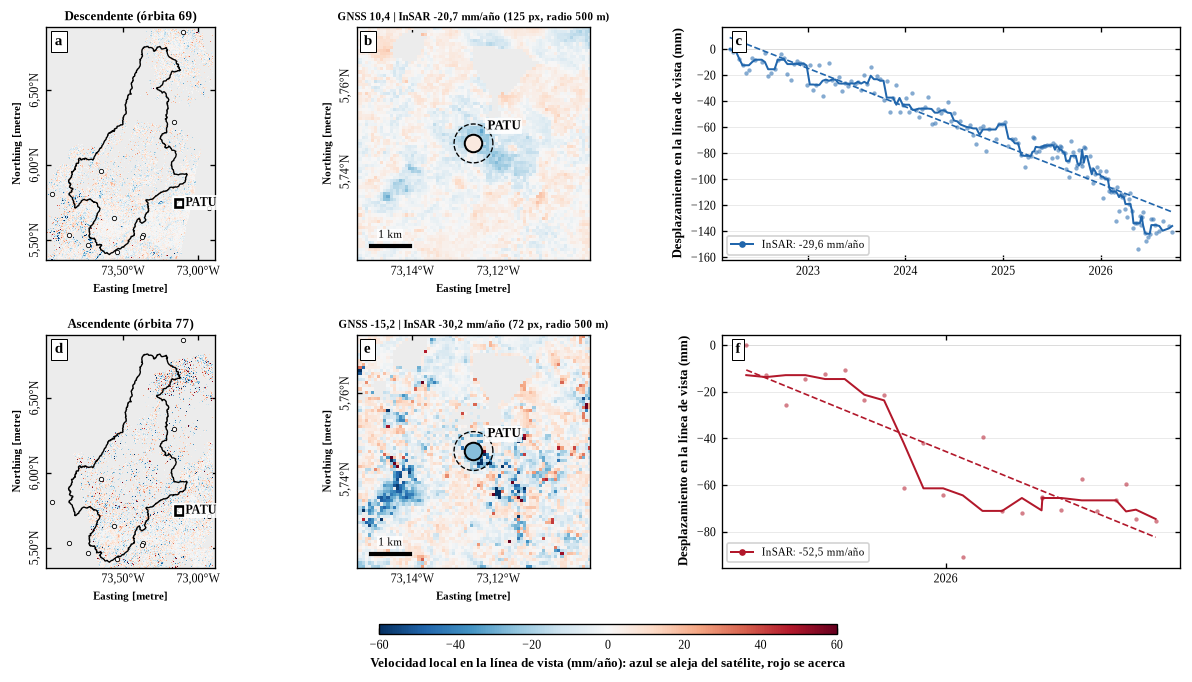

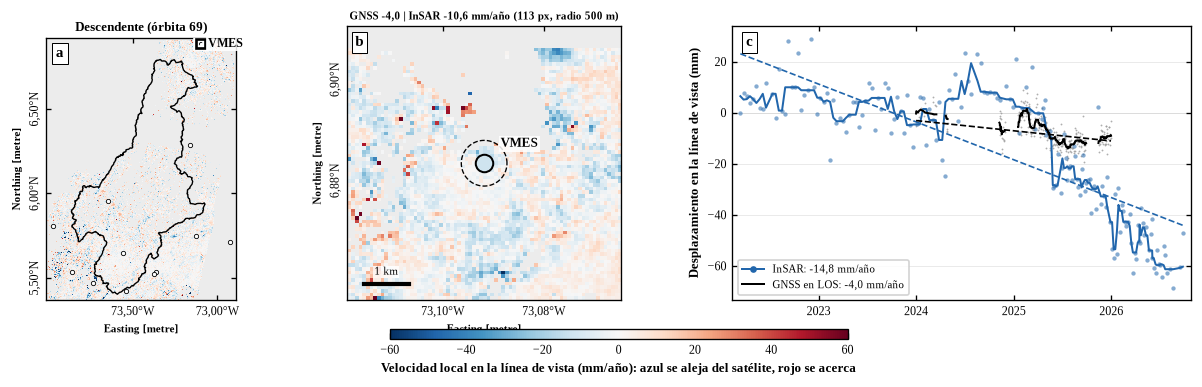

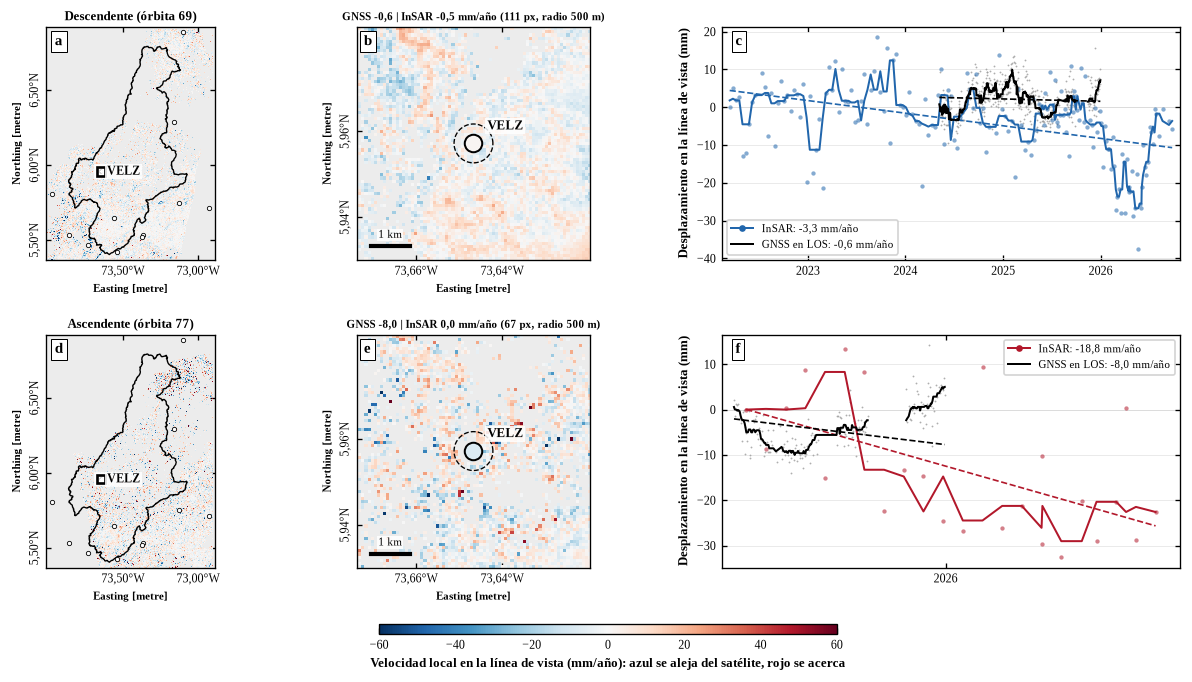

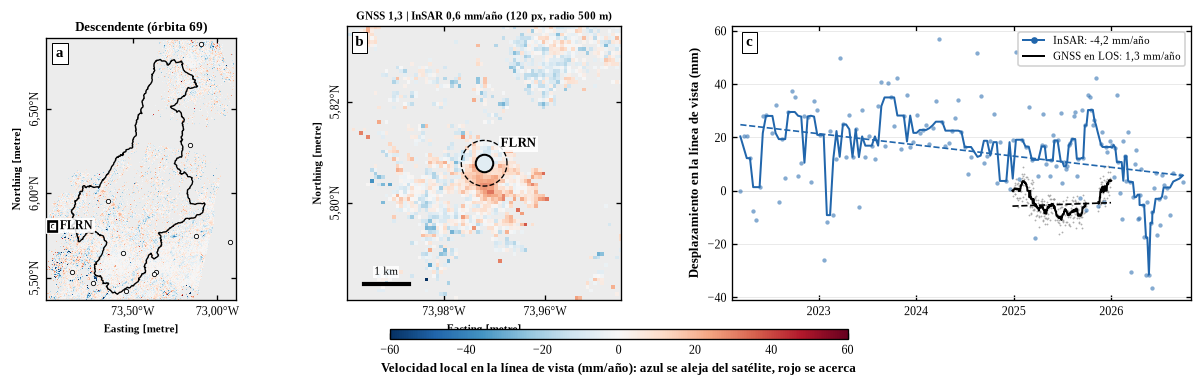

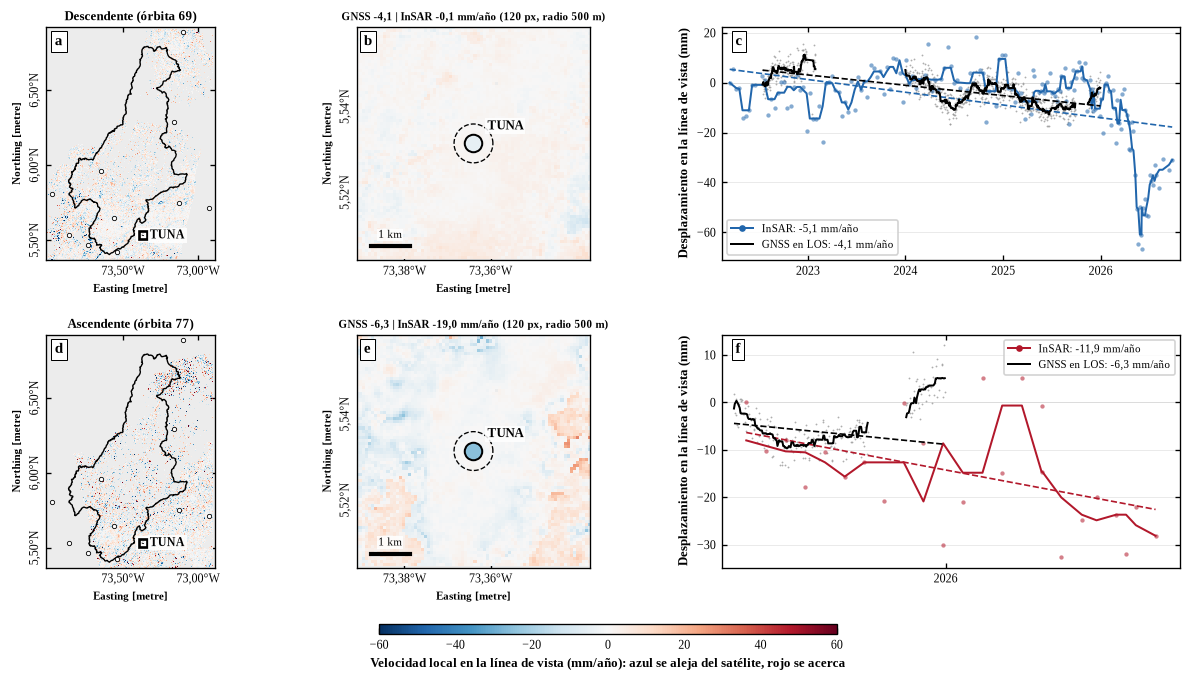

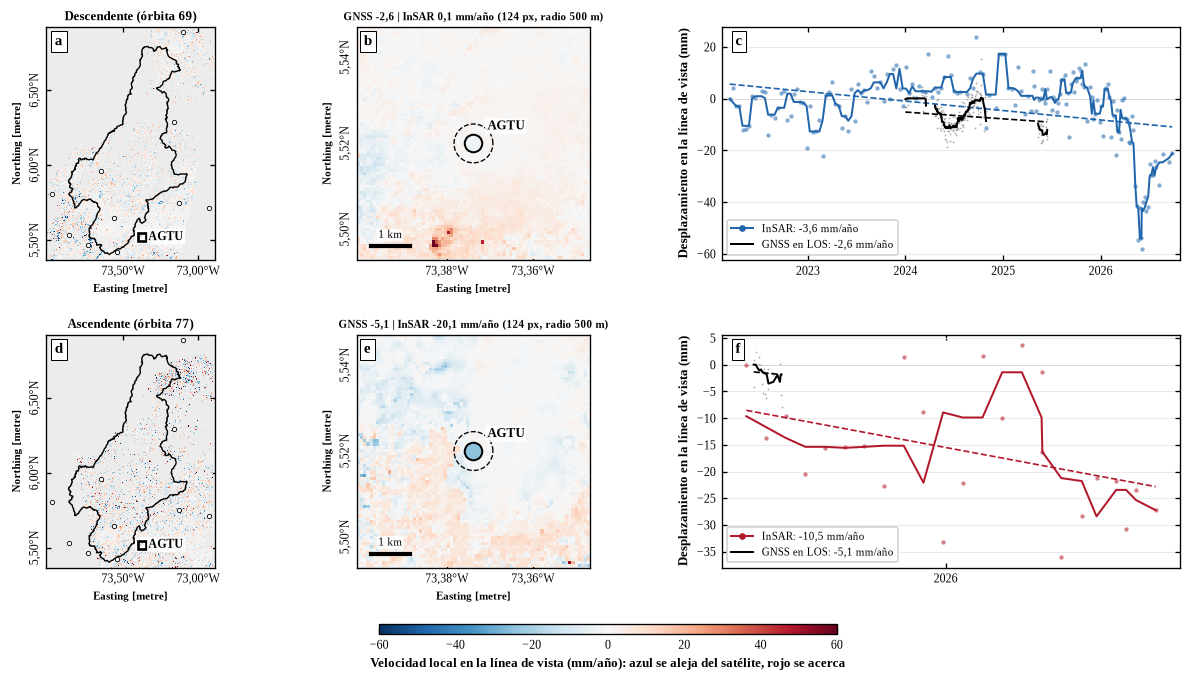

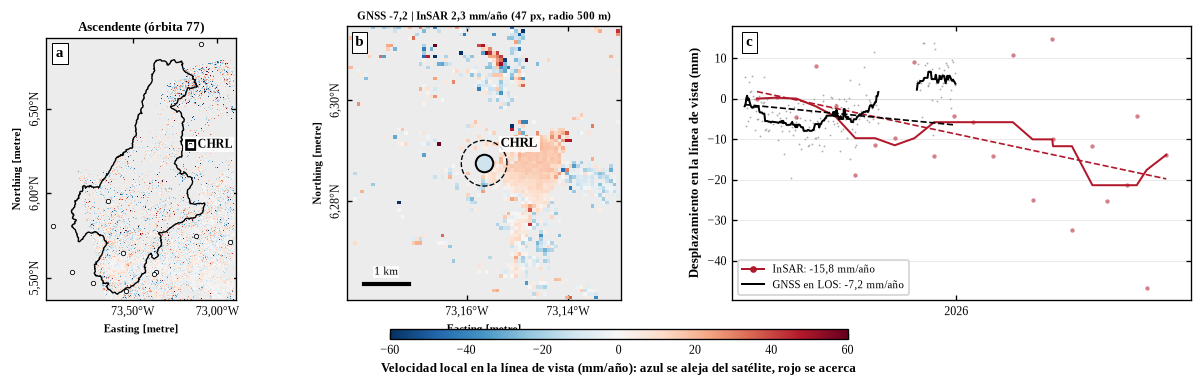

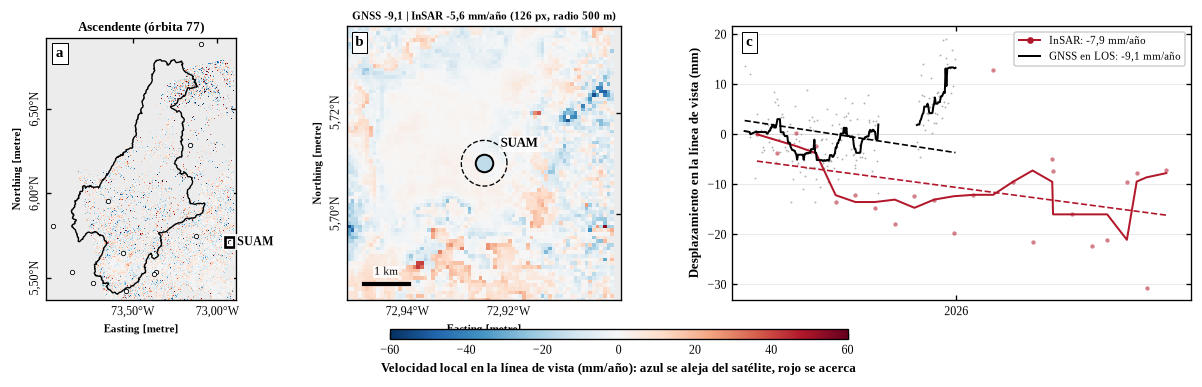

ok: 8 estaciones con comparación | tablas y figuras en /home/jovyan/Tesis_InSAR_Rio_Suarez/03_resultados/integracion


In [7]:
if len(comp):
    for estacion in comp["Estación"].unique():
        figura_estacion(estacion)
    print(f"ok: {comp['Estación'].nunique()} estaciones con comparación | tablas y figuras en {SALIDA_DIR}")
else:
    print("sin comparaciones: ninguna estación tiene velocidad GNSS y píxeles InSAR confiables; revise RADIOS_INSAR_M y los mosaicos")

## Referencias

Bevis, M. y Brown, A. (2014). Trajectory models and reference frames for crustal motion geodesy. *Journal of Geodesy, 88*(3), 283-311. https://doi.org/10.1007/s00190-013-0685-5

Blewitt, G., Hammond, W. C. y Kreemer, C. (2018). Harnessing the GPS data explosion for interdisciplinary science. *Eos, 99*. https://doi.org/10.1029/2018EO104623

Hanssen, R. F. (2001). *Radar interferometry: Data interpretation and error analysis*. Kluwer Academic Publishers. https://doi.org/10.1007/0-306-47633-9

Hogenson, K., Kristenson, H., Kennedy, J., Johnston, A., Rine, J., Logan, T., Zhu, J., Williams, F., Herrmann, J., Smale, J., y Meyer, F. (2026). *HyP3* [Software]. Alaska Satellite Facility. https://hyp3-docs.asf.alaska.edu/

Hu, J., Li, Z.-W., Ding, X.-L., Zhu, J.-J., Zhang, L. y Sun, Q. (2014). Resolving three-dimensional surface displacements from InSAR measurements: A review. *Earth-Science Reviews, 133*, 1-17. https://doi.org/10.1016/j.earscirev.2014.02.005

Sun, Q., Zhang, L., Ding, X. L., Hu, J., Li, Z. W. y Zhu, J. J. (2015). Slope deformation prior to Zhouqu, China landslide from InSAR time series analysis. *Remote Sensing of Environment, 156*, 45-57. https://doi.org/10.1016/j.rse.2014.09.029

Williams, S. D. P. (2003). The effect of coloured noise on the uncertainties of rates estimated from geodetic time series. *Journal of Geodesy, 76*(9-10), 483-494. https://doi.org/10.1007/s00190-002-0283-4

Yunjun, Z., Fattahi, H. y Amelung, F. (2019). Small baseline InSAR time series analysis: Unwrapping error correction and noise reduction. *Computers & Geosciences, 133*, 104331. https://doi.org/10.1016/j.cageo.2019.104331